# Milestone 1 - Visual grapheme extraction

**Goal (proposal):** an image pipeline that takes a photo of a seal inscription and outputs an ordered list of standardized sign IDs.

**Summary:** detection works on real inscription strips; recognition of *which* of the 417 signs does not (17% top-1). This notebook loads saved results only.

*Regenerate:* training scripts in `src/m1_vision/` (see `src/m1_vision/README.md`); real-strip evaluation `python src/m1_vision/read_strip.py --all --review`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in ("src", "src/m3_masking", "src/m4_guardrails", "src/m2_markov", "src/m1_vision"):
    sys.path.insert(0, str(ROOT / p))
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

## 1. Dataset audit: one template per sign
The Kaggle IM-417-150 set has **exactly one image per sign**, a one-shot problem. It cannot be used as a training set in the usual sense.

template images: 417 | images per class: 1


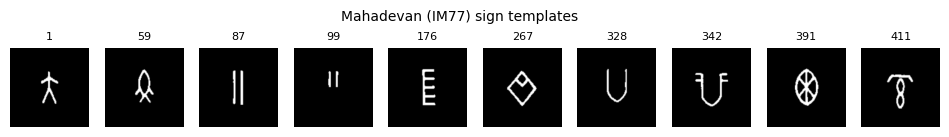

In [2]:
tpl = sorted((ROOT / "data/raw/IM_417_150_PNG").glob("*.png"), key=lambda p: int(p.stem))
print("template images:", len(tpl), "| images per class: 1")
fig, ax = plt.subplots(1, 10, figsize=(12, 1.6))
for a, p in zip(ax, [tpl[i] for i in (0, 58, 86, 98, 175, 266, 327, 341, 390, 410)]):
    a.imshow(plt.imread(p), cmap="gray"); a.set_title(p.stem, fontsize=8); a.axis("off")
plt.suptitle("Mahadevan (IM77) sign templates", fontsize=10); plt.show()

## 2. Synthetic training data
We generated labelled training data by composing templates into carved-relief inscriptions. Below: real inscriptions from the M3 test split drawn by the `strip` renderer (used by the engine evaluation).

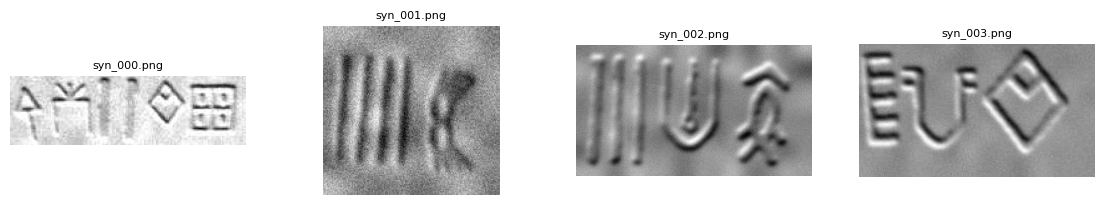

In [3]:
imgs = sorted((ROOT / "data/processed/engine_synthetic/images").glob("*.png"))[:4]
fig, ax = plt.subplots(1, len(imgs), figsize=(14, 2.2))
for a, p in zip(ax, imgs): a.imshow(plt.imread(p), cmap="gray"); a.axis("off"); a.set_title(p.name, fontsize=8)
plt.show()

## 3. Detector training curves (YOLOv8n, single class `sign`)
Learning curves and loss charts from `runs/sign_detector/results.csv`.

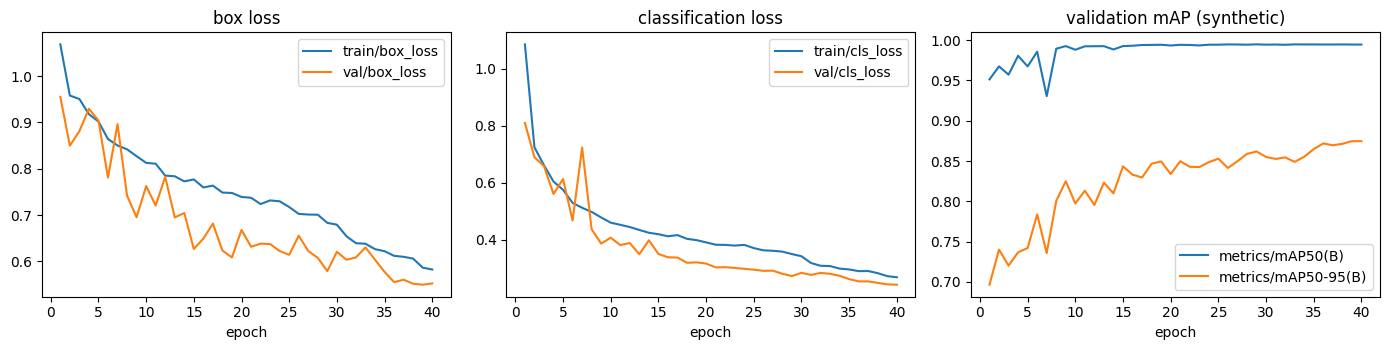

final mAP50 0.995, mAP50-95 0.875 (synthetic validation)


In [4]:
r = pd.read_csv(ROOT / "runs/sign_detector/results.csv"); r.columns = [c.strip() for c in r.columns]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for c in ("train/box_loss", "val/box_loss"): ax[0].plot(r.epoch, r[c], label=c)
ax[0].set(title="box loss", xlabel="epoch"); ax[0].legend()
for c in ("train/cls_loss", "val/cls_loss"): ax[1].plot(r.epoch, r[c], label=c)
ax[1].set(title="classification loss", xlabel="epoch"); ax[1].legend()
for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"): ax[2].plot(r.epoch, r[c], label=c)
ax[2].set(title="validation mAP (synthetic)", xlabel="epoch"); ax[2].legend(); plt.tight_layout(); plt.show()
print(f"final mAP50 {r['metrics/mAP50(B)'].iloc[-1]:.3f}, mAP50-95 {r['metrics/mAP50-95(B)'].iloc[-1]:.3f} (synthetic validation)")

## 4. Recognizer training curves (MobileNetV3-Small, 417 classes, synthetic crops)

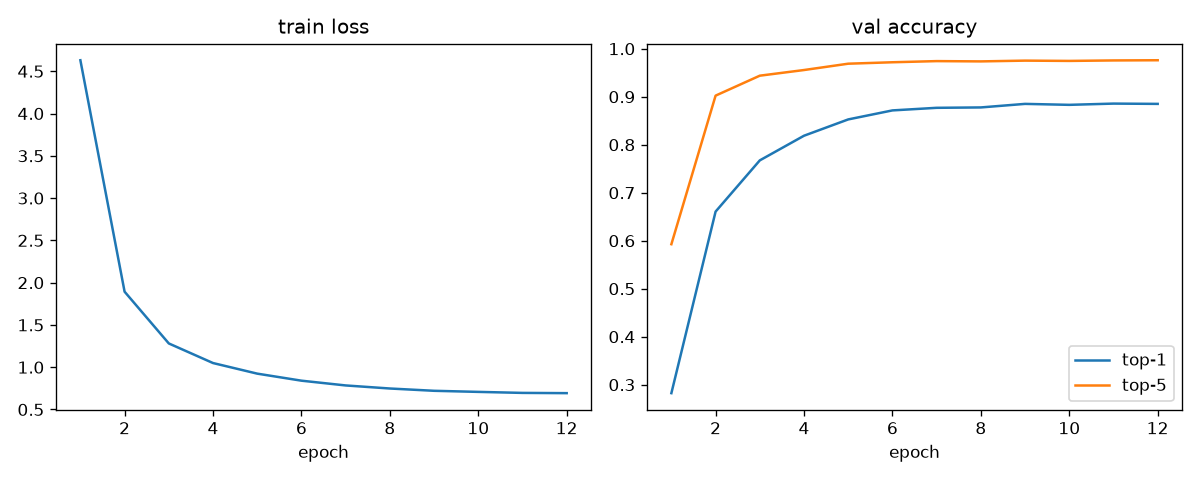

In [5]:
display(Image(filename=str(ROOT / "reports/figures/recognizer_curves.png"), width=900))

**Validation is synthetic only.** No cross-validation on real data is possible, because there is no labelled real data. The real-data evaluation below is a hand review.

## 5. Real inscription strips (77 strips, Indus-Seal-Dataset)

In [6]:
s = pd.read_csv(ROOT / "reports/strip_eval.csv")
print(f"strips: {len(s)} | with >=1 detection: {(s.n_signs>0).mean():.0%} | signs per strip: mean {s.n_signs.mean():.1f}, median {s.n_signs.median():.0f}")
rows = []
for name, f in (("baseline recognizer", "strip_review_baseline.csv"), ("+ strip-domain crops", "strip_review_recog.csv")):
    v = pd.read_csv(ROOT / "reports" / f).verdict.value_counts(); n = len(pd.read_csv(ROOT / "reports" / f))
    signs = n - v.get("not_a_sign", 0); t1 = v.get("top1_correct", 0); t5 = t1 + v.get("top5_correct", 0)
    rows.append(dict(attempt=name, judged=n, detection_precision=f"{signs/n:.0%}",
                     top1=f"{t1/signs:.0%} [{wilson(t1,signs)[0]:.0%}-{wilson(t1,signs)[1]:.0%}]",
                     top5=f"{t5/signs:.0%} [{wilson(t5,signs)[0]:.0%}-{wilson(t5,signs)[1]:.0%}]"))
display(pd.DataFrame(rows))

strips: 77 | with >=1 detection: 99% | signs per strip: mean 4.9, median 5


,attempt,judged,detection_precision,top1,top5
0,baseline recognizer,70,77%,17% [9%-29%],41% [29%-54%]
1,+ strip-domain crops,70,86%,12% [6%-22%],40% [29%-53%]


Hand-judged random samples of 70 detections, with 95% Wilson intervals. Chance top-1 over 417 signs is 0.24%.

Two further attempts are not in the table. A relief-to-line-art U-Net collapsed to 17 sign IDs, and binarization was clearly worse; both are documented in `reports/MILESTONE1_SUMMARY.md`.

## 6. The sim-to-real gap, measured end to end
The same reader applied to real inscriptions drawn synthetically (truth known) vs real photographs (`src/engine/eval_synthetic.py`).

In [7]:
e = json.load(open(ROOT / "reports/engine/synthetic_eval.json")); rr = e["recognition_on_count_matched"]
display(pd.DataFrame([dict(input="synthetic strips (truth known)", signs=rr["signs"], top1=f"{rr['top1']:.1%}", top5=f"{rr['top5']:.1%}", exact_sequence=f"{rr['exact_sequence']:.0%}"),
                      dict(input="real strips, saved (strip-domain) recognizer, hand review", signs=60, top1="12%", top5="40%", exact_sequence="-"),
                      dict(input="real strips, baseline recognizer (weights overwritten), hand review", signs=54, top1="17%", top5="41%", exact_sequence="-")]))
print("The synthetic row and the first real row use the same saved weights, so they are the like-for-like comparison.")

,input,signs,top1,top5,exact_sequence
0,synthetic strips (truth known),340,87.9%,96.8%,70%
1,"real strips, saved (strip-domain) recognizer, hand review",60,12%,40%,-
2,"real strips, baseline recognizer (weights overwritten), ...",54,17%,41%,-


The synthetic row and the first real row use the same saved weights, so they are the like-for-like comparison.


## Limitations
- There are no ground-truth transcriptions for the real strips, so recognition is measured by hand review of samples only.
- All training data is synthetic, and the gap between synthetic (88%) and real (17%) accuracy is the main finding.
- The pipeline assumes impression-orientation input (a mirror test on 262 crops found no evidence the strips are mirrored).
- The crosswalk maps 334 of the 417 IM77 signs to Wells numbers; the other 83 have no equivalent.